# Étude progressive des réseaux de neurones sur le jeu de données HAR

**Projet de Deep Learning, M2 MALIA, 2026-2027** (enseignant : Walid Bechkit)
**Auteur :** Martine Ouedraogo
**Ce notebook :** Version 1, réseau à une seule couche cachée (baseline)

## Objectif du projet

Je veux reconnaître l'activité d'une personne à partir des mesures des capteurs de son smartphone (accéléromètre et gyroscope). Il y a 6 activités : WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS, SITTING, STANDING et LAYING.

Je pars d'une référence simple (une régression logistique), puis je construis des réseaux de neurones de plus en plus complexes pour voir ce qu'apportent la taille du réseau, les fonctions d'activation, les optimiseurs et la régularisation. Mon but est de comprendre et de justifier mes choix, pas d'obtenir la meilleure accuracy.

Les règles que je suis (demandées dans l'énoncé) :
- tous les choix se font sur un ensemble de validation composé de volontaires entiers ;
- les comparaisons importantes sont répétées avec plusieurs graines (moyenne ± écart-type) ;
- le jeu de test n'est utilisé qu'une seule fois, à la fin ;
- les graines aléatoires sont fixées pour que les résultats soient reproductibles.

## Plan du notebook

La numérotation est celle de l'énoncé : une **Partie** (1, 2, 3…), puis ses questions (1.1, 1.2…), puis mes étapes (1.2.1, 1.2.2…).

| Partie | Sujet | Dans ce notebook (Version 1) | État |
|---|---|---|---|
| 1 | Jeu de données : exploration, validation, référence | 1.1 à 1.4 | fait |
| 2 | Première architecture (une couche cachée) | 2.1 à 2.3 | fait |
| 3 | Extension de l'architecture | 3.1 (taille de la couche cachée) | à faire |
| 5 | Visualisation et analyse des performances | 5.1 et 5.2 | à faire |

Les parties qui demandent un réseau plus profond ou davantage d'outils (3.2, 4 régularisation, 6 t-SNE/UMAP, 7 bonus) iront dans le notebook Version 2.

**Ordre des cellules du notebook, selon la structure de code imposée par l'énoncé (8.1) :**

| Structure 8.1 | Où la trouver |
|---|---|
| 1. Imports | Préliminaires |
| 2. Chargement et exploration des données | 1.1, 1.2 |
| 3. Découpage apprentissage / validation et DataLoaders | 1.3 (découpage) ; DataLoaders en tête de la Partie 2 |
| 4. Modèle et fonctions d'entraînement / évaluation | 2.1 |
| 5. Boucle d'entraînement principale | 2.2, 2.3, 3.1 |
| 6. Visualisation et comparaison des résultats | 5.1 |
| 7. Évaluation finale sur le jeu de test | 5.2 |

Les étapes suivent bien l'ordre 1 → 7 de l'énoncé. Une précision : la référence 1.4 (régression logistique) est placée entre l'étape 3 (découpage) et l'étape 4 (modèle), car l'énoncé la met dans la Partie 1. Les DataLoaders (fin de l'étape 3) sont préparés en tête de la Partie 2, juste avant le premier réseau.

## Préliminaires : imports et graine aléatoire

J'utilise numpy et pandas pour les données, matplotlib et seaborn pour les graphiques, et scikit-learn pour la référence. PyTorch sera importé quand je construirai les réseaux. Je fixe la graine aléatoire dès le début.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Graine fixée pour la reproductibilité
SEED = 42
np.random.seed(SEED)

# Partie 1 : Jeu de données

> **Ce qui est demandé dans cette partie :** charger le jeu de données HAR (1.1), l'explorer et discuter du prétraitement (1.2), construire un ensemble de validation par volontaire (1.3), puis entraîner une régression logistique de référence (1.4).

## 1.1 Présentation et chargement du jeu de données

> **Demandé :** charger `train.csv` et `test.csv`. Chaque ligne est une fenêtre de mesures d'un volontaire, décrite par des centaines de variables. La cible est `Activity` (6 classes), la colonne `subject` indique le volontaire, et les volontaires du test ne sont pas dans le train.

Je charge les deux fichiers. Le test ne me sert ici qu'à décrire les données : je n'évalue aucun modèle dessus avant la partie 5.2.

In [2]:
train = pd.read_csv("HAR/train.csv")
test = pd.read_csv("HAR/test.csv")

# Aperçu : deux variables, puis les colonnes subject (volontaire) et Activity (cible)
train[["tBodyAcc-mean()-X", "tBodyAcc-std()-X", "subject", "Activity"]].head()

,tBodyAcc-mean()-X,tBodyAcc-std()-X,subject,Activity
0,0.288585,-0.995279,1,STANDING
1,0.278419,-0.998245,1,STANDING
2,0.279653,-0.995380,1,STANDING
3,0.279174,-0.996091,1,STANDING
4,0.276629,-0.998139,1,STANDING


Chaque ligne est une fenêtre de 2,56 secondes de mesures. Sur ces 5 premières lignes, c'est le même volontaire (le n°1) qui reste debout, et je remarque que les valeurs de `tBodyAcc-mean()-X` sont presque identiques d'une ligne à l'autre (environ 0,28). J'y reviens en 1.3.1 : les fenêtres consécutives se chevauchent.

## 1.2 Prise en main exploratoire

> **Demandé :**
> - (a) afficher le nombre d'observations, de variables et de volontaires de chaque fichier ;
> - (b) examiner la distribution des classes ;
> - (c) calculer des statistiques descriptives (moyenne, écart-type, minimum, maximum) ;
> - (d) produire quelques visualisations simples (histogrammes, boxplots, corrélations) ;
> - (e) discuter des besoins de prétraitement (normalisation, encodage, suppression de colonnes) : les variables sont-elles déjà mises à l'échelle ? La colonne `subject` doit-elle servir d'entrée au modèle ?

Je traite ces points dans l'ordre : 1.2.1 (a), 1.2.2 (b), 1.2.3 (c), 1.2.4 (d), puis 1.2.5 (qualité des données) et 1.2.6 (e).

### 1.2.1 Nombre d'observations, de variables et de volontaires (a)

Je compte les observations, les variables et les volontaires de chaque fichier. Je retire 2 colonnes du nombre de variables, car `subject` et `Activity` ne sont pas des mesures.

In [3]:
for nom, df in [("Train", train), ("Test", test)]:
    print(f"{nom} : {df.shape[0]} observations, {df.shape[1] - 2} variables, "
          f"{df['subject'].nunique()} volontaires")

# Y a-t-il des volontaires à la fois dans le train et dans le test ?
print("Volontaires communs au train et au test :", set(train["subject"]) & set(test["subject"]))

Train : 7352 observations, 561 variables, 21 volontaires
Test : 2947 observations, 561 variables, 9 volontaires
Volontaires communs au train et au test : set()


Je constate que les deux fichiers ont les mêmes 561 variables : 7352 fenêtres de 21 volontaires pour le train, 2947 fenêtres de 9 volontaires pour le test. Aucun volontaire n'est commun aux deux. Le test mesure donc bien la capacité du modèle à reconnaître des personnes qu'il n'a jamais vues.

### 1.2.2 Distribution des classes (b)

Je regarde la proportion de chaque activité dans le train et dans le test. Je compare en pourcentages, car les deux fichiers n'ont pas la même taille.

                    train  test
Activity                       
LAYING               19.1  18.2
SITTING              17.5  16.7
STANDING             18.7  18.1
WALKING              16.7  16.8
WALKING_DOWNSTAIRS   13.4  14.3
WALKING_UPSTAIRS     14.6  16.0
Rapport max/min : 1.43


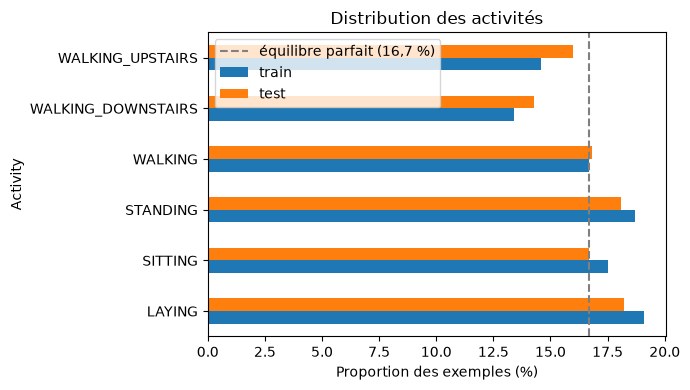

In [4]:
prop = pd.DataFrame({
    "train": train["Activity"].value_counts(normalize=True) * 100,
    "test": test["Activity"].value_counts(normalize=True) * 100,
}).round(1)
print(prop)

# Rapport entre la classe la plus fréquente et la plus rare (train)
effectifs = train["Activity"].value_counts()
print("Rapport max/min :", round(effectifs.max() / effectifs.min(), 2))

prop.plot(kind="barh", figsize=(7, 4))
plt.axvline(100 / 6, color="gray", linestyle="--", label="équilibre parfait (16,7 %)")
plt.xlabel("Proportion des exemples (%)")
plt.title("Distribution des activités")
plt.legend()
plt.tight_layout()
plt.show()

La classe la plus fréquente est LAYING (1407 fenêtres) et la plus rare WALKING_DOWNSTAIRS (986), soit un rapport de 1,4. Les classes sont plutôt équilibrées et leurs proportions sont proches entre le train et le test. L'accuracy ne sera donc pas trompeuse ici, mais je suivrai quand même le F1 par classe.

### 1.2.3 Statistiques descriptives (c)

Un `describe()` complet fait 561 colonnes et n'est pas lisible. Je calcule donc la moyenne, l'écart-type, le minimum et le maximum de chaque variable, puis je résume ces 4 statistiques sur l'ensemble des variables.

In [5]:
X_train = train.drop(columns=["subject", "Activity"])
stats = X_train.describe().T[["mean", "std", "min", "max"]]
print(stats.describe().round(3))

print()
print("Variables dont le min vaut -1 :", (stats["min"] == -1).sum())
print("Variables dont le max vaut 1  :", (stats["max"] == 1).sum())
print("Moyennes : de", round(stats["mean"].min(), 3), "à", round(stats["mean"].max(), 3))
print("Écarts-types : de", round(stats["std"].min(), 3), "à", round(stats["std"].max(), 3))

          mean      std      min      max
count  561.000  561.000  561.000  561.000
mean    -0.508    0.284   -0.990    0.978
std      0.428    0.137    0.050    0.069
min     -0.984    0.041   -1.000    0.465
25%     -0.868    0.192   -1.000    1.000
50%     -0.659    0.265   -1.000    1.000
75%     -0.108    0.362   -1.000    1.000
max      0.830    0.752   -0.494    1.000

Variables dont le min vaut -1 : 466
Variables dont le max vaut 1  : 452
Moyennes : de -0.984 à 0.83
Écarts-types : de 0.041 à 0.752


Je remarque que toutes les variables sont bornées dans [-1, 1] (466 atteignent -1 et 452 atteignent 1). Les auteurs ont donc fait une normalisation min-max. En revanche, les moyennes vont de -0,98 à 0,83 et les écarts-types de 0,04 à 0,75 : les variables ne sont pas standardisées.

### 1.2.4 Visualisations (d)

**1.2.4 (i) Histogrammes.** Je compare deux variables de nature différente : une moyenne et un écart-type du signal d'accélération du corps sur l'axe X.

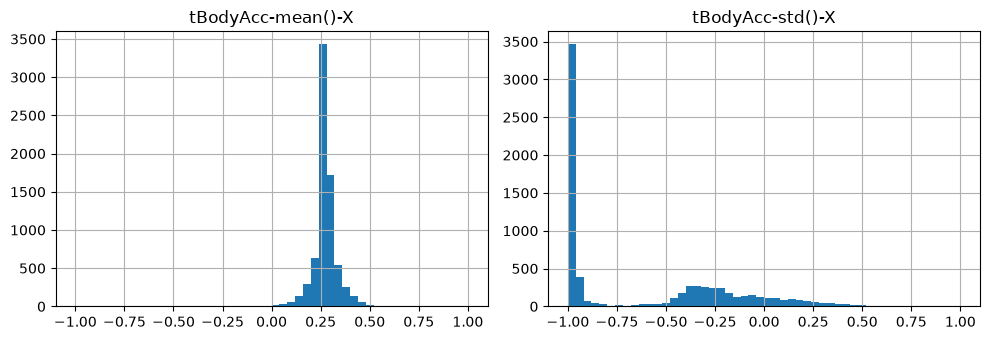

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col in zip(axes, ["tBodyAcc-mean()-X", "tBodyAcc-std()-X"]):
    X_train[col].hist(bins=50, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

La première variable a une seule bosse très serrée autour de 0,27 (quelques valeurs isolées à -1 et 1 étirent l'axe). La seconde est très différente : un énorme pic collé à -1 et une bosse plus étalée entre -0,5 et 0,5. Je suppose que le pic correspond aux activités immobiles et la bosse aux marches. Je le vérifie en colorant l'histogramme par activité.

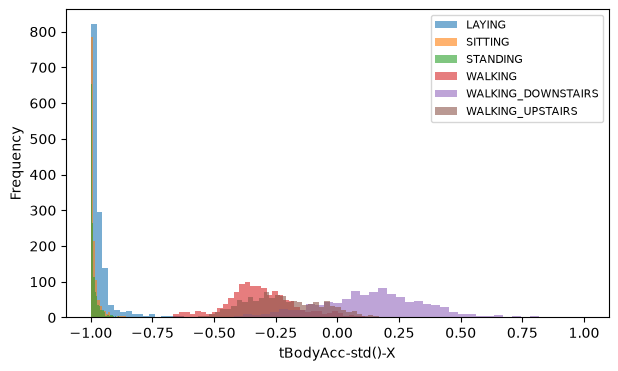

In [7]:
col = "tBodyAcc-std()-X"
plt.figure(figsize=(7, 4))
for activite, groupe in train.groupby("Activity"):
    groupe[col].plot(kind="hist", bins=40, alpha=0.6, label=activite)
plt.xlabel(col)
plt.legend(fontsize=8)
plt.show()

Je constate que les trois activités immobiles (SITTING, STANDING, LAYING) sont empilées autour de -1, alors que les trois marches s'en détachent, WALKING_DOWNSTAIRS étant la plus à droite. Cette variable sépare donc bien « immobile » et « en mouvement », mais elle ne distingue pas les trois activités immobiles entre elles.

**1.2.4 (ii) Boxplots.** Je compare 2 variables selon l'activité : un angle par rapport à la gravité, et l'écart-type de l'accélération.

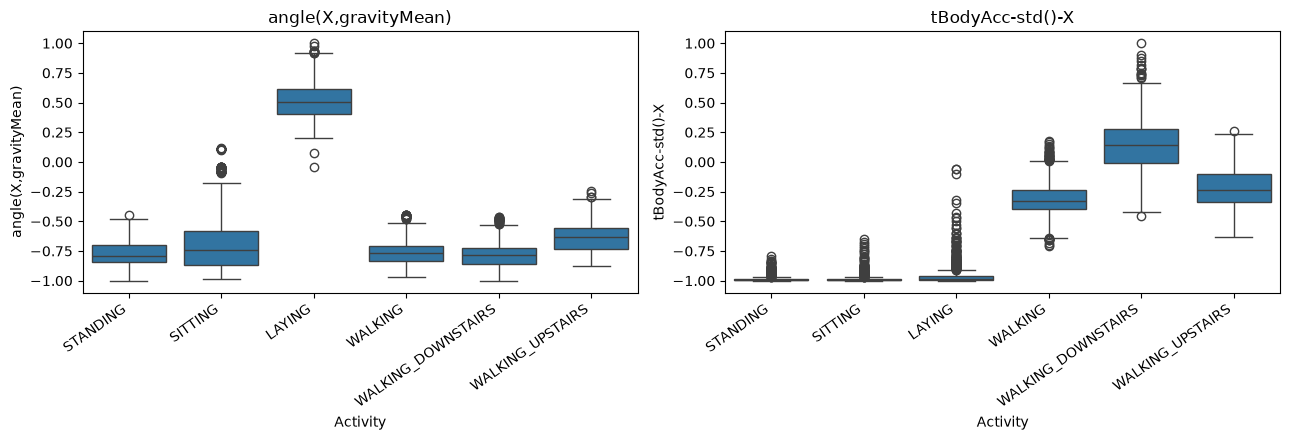

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col in zip(axes, ["angle(X,gravityMean)", "tBodyAcc-std()-X"]):
    sns.boxplot(data=train, x="Activity", y=col, ax=ax)
    ax.set_title(col)
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
plt.tight_layout()
plt.show()

Pour `angle(X,gravityMean)`, LAYING est loin au-dessus des autres (médiane de 0,51 contre -0,6 à -0,8) : quand le téléphone est couché, son angle avec la gravité change complètement. Pour `tBodyAcc-std()-X`, les trois activités immobiles ont des boîtes minuscules collées à -1 et les marches s'en détachent, mais WALKING et WALKING_UPSTAIRS se chevauchent en partie. Sur ces deux variables, SITTING et STANDING restent mélangées : je m'attends à ce que ce soit une paire difficile pour le modèle. Chaque variable ne raconte qu'une partie de l'histoire, ce qui justifie de les combiner dans un réseau.

**1.2.4 (iii) Corrélations.** Je calcule la matrice de corrélation des 561 variables. Je masque leurs noms, trop nombreux, et je compte les paires très corrélées.

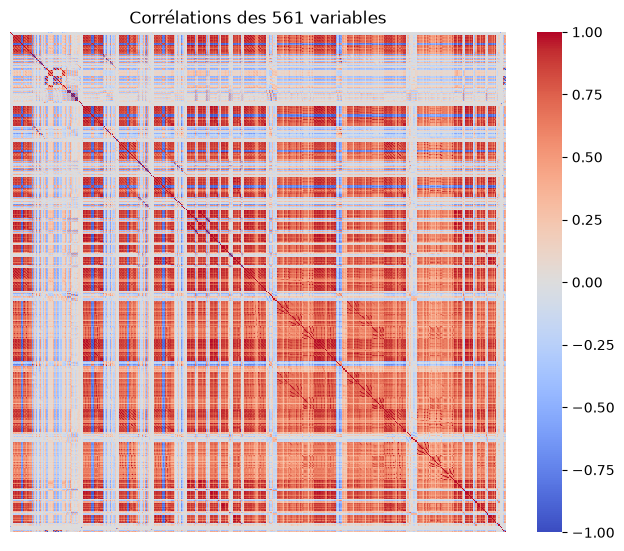

Nombre de paires de variables : 157080
Paires avec |r| > 0.9 : 8206 (5.2 %)


In [9]:
corr_all = X_train.corr()

plt.figure(figsize=(8, 6.5))
sns.heatmap(corr_all, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            xticklabels=False, yticklabels=False)
plt.title("Corrélations des 561 variables")
plt.show()

# Chaque paire est comptée une seule fois (triangle supérieur de la matrice)
absc = corr_all.abs().to_numpy()
haut = absc[np.triu_indices_from(absc, k=1)]
print("Nombre de paires de variables :", len(haut))
print("Paires avec |r| > 0.9 :", (haut > 0.9).sum(), f"({(haut > 0.9).mean() * 100:.1f} %)")

Je vois de grands blocs rouges : ce sont des variables qui mesurent la même chose sous plusieurs formes (écart-type, MAD, IQR, énergie d'un même signal). Il y a aussi des bandes bleues (les minimums, anticorrélés avec ces mesures de dispersion) et des bandes grises (variables presque indépendantes, comme les moyennes). 8206 paires (5,2 %) ont une corrélation supérieure à 0,9 en valeur absolue : l'information est très redondante. Un MLP supporte bien cela, mais je le garde en tête.

### 1.2.5 Qualité des données

Pour décider du prétraitement, je cherche les valeurs manquantes, les doublons, les colonnes constantes, les valeurs hors de [-1, 1] et les valeurs extrêmes.

In [10]:
# Valeurs manquantes et lignes dupliquées
print("Valeurs manquantes  train :", train.isna().sum().sum(), "| test :", test.isna().sum().sum())
print("Lignes dupliquées   train :", train.duplicated().sum(), "| test :", test.duplicated().sum())

# Colonnes constantes et colonnes copies exactes d'une autre
print("Colonnes constantes :", (X_train.nunique() <= 1).sum())
colonnes_copies = X_train.T.duplicated()
print("Colonnes copies d'une autre :", colonnes_copies.sum())
print(list(X_train.columns[colonnes_copies.to_numpy()]))

# Valeurs hors de [-1, 1]
X_test = test.drop(columns=["subject", "Activity"])
print("Valeurs hors [-1,1] train :", (X_train.abs() > 1).sum().sum(),
      "| test :", (X_test.abs() > 1).sum().sum())

# Valeurs extrêmes : règle des boxplots (1,5 x IQR) puis z-score
Q1, Q3 = X_train.quantile(0.25), X_train.quantile(0.75)
IQR = Q3 - Q1
hors_moustaches = (X_train < Q1 - 1.5 * IQR) | (X_train > Q3 + 1.5 * IQR)
print("% de valeurs hors moustaches :", round(hors_moustaches.to_numpy().mean() * 100, 1))
Z = ((X_train - X_train.mean()) / X_train.std()).abs()
print("Valeurs avec |z| > 5  :", (Z > 5).sum().sum())
print("Valeurs avec |z| > 10 :", (Z > 10).sum().sum(), "| z maximal :", round(Z.max().max(), 1))

Valeurs manquantes  train : 0 | test : 0
Lignes dupliquées   train : 0 | test : 0


Colonnes constantes : 0


Colonnes copies d'une autre : 21
['tBodyAccMag-sma()', 'tGravityAccMag-mean()', 'tGravityAccMag-std()', 'tGravityAccMag-mad()', 'tGravityAccMag-max()', 'tGravityAccMag-min()', 'tGravityAccMag-sma()', 'tGravityAccMag-energy()', 'tGravityAccMag-iqr()', 'tGravityAccMag-entropy()', 'tGravityAccMag-arCoeff()1', 'tGravityAccMag-arCoeff()2', 'tGravityAccMag-arCoeff()3', 'tGravityAccMag-arCoeff()4', 'tBodyAccJerkMag-sma()', 'tBodyGyroMag-sma()', 'tBodyGyroJerkMag-sma()', 'fBodyAccMag-sma()', 'fBodyBodyAccJerkMag-sma()', 'fBodyBodyGyroMag-sma()', 'fBodyBodyGyroJerkMag-sma()']
Valeurs hors [-1,1] train : 0 | test : 0
% de valeurs hors moustaches : 4.0
Valeurs avec |z| > 5  : 7415
Valeurs avec |z| > 10 : 658 | z maximal : 34.2


Je constate que les données sont propres : pas de valeur manquante, de ligne dupliquée, de colonne constante ni de valeur hors de [-1, 1]. En revanche, 21 colonnes sont des copies exactes d'une autre. Par exemple, les `tGravityAccMag-*` sont identiques aux `tBodyAccMag-*`, et les `-sma()` des signaux de magnitude sont identiques aux `-mean()`.

Environ 4 % des valeurs sortent des moustaches des boxplots, mais je ne les considère pas comme aberrantes. Elles restent bornées dans [-1, 1] et viennent surtout des activités dynamiques (variables à deux bosses) : ce sont de vraies mesures, pas des erreurs de capteur.

### 1.2.6 Discussion et choix de prétraitement (e)

Je retire les 21 colonnes copies (repérées sur le train, puis la même liste est appliquée au test), et j'encode la cible en entiers.

In [11]:
colonnes_copies = set(X_train.columns[X_train.T.duplicated().to_numpy()])
feature_cols = [c for c in X_train.columns if c not in colonnes_copies]
print("Variables conservées :", len(feature_cols))

X_train = train[feature_cols]
X_test = test[feature_cols]
print(X_train.shape, X_test.shape)

# Encodage de la cible : un entier par activité (ordre alphabétique)
encoder = LabelEncoder()
y_train = encoder.fit_transform(train["Activity"])
y_test = encoder.transform(test["Activity"])
print({c: i for i, c in enumerate(encoder.classes_)})

Variables conservées : 540
(7352, 540) (2947, 540)
{'LAYING': 0, 'SITTING': 1, 'STANDING': 2, 'WALKING': 3, 'WALKING_DOWNSTAIRS': 4, 'WALKING_UPSTAIRS': 5}


**Réponses aux questions de l'énoncé et choix retenus**

- **Les variables sont-elles déjà mises à l'échelle ?** En partie. Elles sont toutes dans [-1, 1], mais leurs moyennes et écarts-types sont très différents. Je les standardiserai, avec une moyenne et un écart-type calculés sur l'entraînement seulement, pour éviter qu'une information de la validation ou du test ne passe dans l'entraînement. Je le fais en 1.3.3, une fois le découpage fait.
- **`subject` doit-il servir d'entrée ?** Non. C'est un identifiant et pas une mesure, et les volontaires du test sont absents du train. Le modèle risquerait d'apprendre à reconnaître des personnes plutôt que des mouvements. Je garde cette colonne seulement pour découper la validation par volontaire.
- **Suppression de colonnes :** je retire les 21 copies exactes, il reste 540 variables. Je garde les variables corrélées et les valeurs extrêmes (voir 1.2.4 et 1.2.5).
- **Encodage :** `Activity` devient un entier de 0 à 5, le format attendu par `CrossEntropyLoss`.

## 1.3 Découpage et ensemble de validation

> **Demandé :** le test ne sert qu'**une seule fois**, à la fin ; tous les choix (architecture, activation, optimiseur, pas d'apprentissage, régularisation, nombre d'époques) se font sur un ensemble de validation extrait de `train.csv`.
> - (a) Construire cet ensemble en réservant quelques volontaires entiers (4 ou 5), pas des lignes tirées au hasard, et expliquer pourquoi : deux fenêtres consécutives d'un même volontaire se chevauchent et se ressemblent beaucoup.
> - (b) Comparer, pour un même modèle, la performance de validation d'un découpage aléatoire et d'un découpage par volontaire. Lequel est le plus proche de la performance de test ? Conclure.

Mes étapes : 1.3.1 (explication de (a)), 1.3.2 (construction de (a)), 1.3.3 (standardisation), 1.3.4 (comparaison (b)) et 1.3.5 (conclusion).

### 1.3.1 Pourquoi découper par volontaire (a)

Les fenêtres durent 2,56 s et se chevauchent de moitié. Je mesure donc à quel point deux fenêtres consécutives se ressemblent (distance entre leurs 561 variables), et je compare avec deux fenêtres de personnes différentes qui font la même activité.

In [12]:
X_brut = train.drop(columns=["subject", "Activity"]).to_numpy()
sub = train["subject"].to_numpy()
act = train["Activity"].to_numpy()

# Paires de lignes consécutives, même volontaire et même activité
memes = (sub[1:] == sub[:-1]) & (act[1:] == act[:-1])
d_consecutives = np.linalg.norm(X_brut[1:] - X_brut[:-1], axis=1)[memes]

# Paires tirées au hasard : volontaires différents, même activité
rng = np.random.RandomState(SEED)
d_autres = []
while len(d_autres) < 5000:
    i, j = rng.randint(0, len(X_brut), 2)
    if sub[i] != sub[j] and act[i] == act[j]:
        d_autres.append(np.linalg.norm(X_brut[i] - X_brut[j]))

print("Distance médiane, lignes consécutives    :", round(np.median(d_consecutives), 2))
print("Distance médiane, volontaires différents :", round(np.median(d_autres), 2))

Distance médiane, lignes consécutives    : 3.37
Distance médiane, volontaires différents : 5.86


Je constate que deux fenêtres consécutives sont nettement plus proches (distance médiane de 3,4) que deux fenêtres de volontaires différents faisant la même activité (5,9). Avec un découpage aléatoire des lignes, une fenêtre de validation aurait presque toujours une voisine quasi identique dans l'entraînement : la validation mesurerait de la mémorisation. En réservant des volontaires entiers, je reproduis la situation du test, c'est-à-dire des personnes jamais vues.

### 1.3.2 Construction de l'entraînement et de la validation (a)

Je regarde d'abord combien de fenêtres chaque volontaire a pour chaque activité.

In [13]:
tableau = pd.crosstab(train["subject"], train["Activity"])
tableau.columns = [c.replace("WALKING_", "") if c != "WALKING" else c for c in tableau.columns]
tableau["Total"] = tableau.sum(axis=1)
tableau = tableau.rename_axis(index="Volontaire", columns=None)
tableau

,LAYING,SITTING,STANDING,WALKING,DOWNSTAIRS,UPSTAIRS,Total
Volontaire,,,,,,,
1,50,47,53,95,49,53,347
3,62,52,61,58,49,59,341
5,52,44,56,56,47,47,302
6,57,55,57,57,48,51,325
7,52,48,53,57,47,51,308
8,54,46,54,48,38,41,281
11,57,53,47,59,46,54,316
14,51,54,60,59,45,54,323
15,72,59,53,54,42,48,328


Chaque volontaire a fait les 6 activités (entre 281 et 409 fenêtres), donc les 6 classes seront présentes en validation, quels que soient les volontaires que je réserve.

Je tire 5 volontaires au hasard avec la graine fixée, puis je vérifie qu'aucun n'est commun aux deux ensembles et que les classes restent équilibrées.

In [14]:
volontaires = sorted(train["subject"].unique().tolist())
rng = np.random.RandomState(SEED)
vol_val = sorted(rng.choice(volontaires, size=5, replace=False).tolist())
print("Volontaires de validation :", vol_val)

masque_val = train["subject"].isin(vol_val)
tr_df = train[~masque_val]     # entraînement : les 16 autres volontaires
val_df = train[masque_val]     # validation : les 5 volontaires réservés

print("Entraînement :", tr_df.shape[0], "fenêtres,", tr_df["subject"].nunique(), "volontaires")
print("Validation   :", val_df.shape[0], "fenêtres,", val_df["subject"].nunique(), "volontaires")
print("Volontaires en commun :", set(tr_df["subject"]) & set(val_df["subject"]))

pd.DataFrame({
    "entraînement (%)": tr_df["Activity"].value_counts(normalize=True) * 100,
    "validation (%)": val_df["Activity"].value_counts(normalize=True) * 100,
}).round(1)

Volontaires de validation : [1, 3, 15, 25, 27]
Entraînement : 5551 fenêtres, 16 volontaires
Validation   : 1801 fenêtres, 5 volontaires
Volontaires en commun : set()


,entraînement (%),validation (%)
Activity,,
LAYING,19.4,18.4
SITTING,17.9,16.3
STANDING,19.0,17.8
WALKING,16.0,18.8
WALKING_DOWNSTAIRS,13.4,13.4
WALKING_UPSTAIRS,14.4,15.3


Le tirage donne les volontaires 1, 3, 15, 25 et 27. J'obtiens 5551 fenêtres d'entraînement (16 volontaires) et 1801 fenêtres de validation (5 volontaires), sans volontaire en commun. Les proportions de classes sont proches dans les deux ensembles (écart maximal de 2,8 points, pour WALKING), donc la validation est représentative.

### 1.3.3 Standardisation (suite du prétraitement de 1.2.6)

Je standardise les variables (moyenne 0, écart-type 1). Le `StandardScaler` est ajusté sur l'entraînement seulement, puis appliqué à la validation.

In [15]:
X_tr = tr_df[feature_cols].to_numpy()
X_val = val_df[feature_cols].to_numpy()
y_tr = encoder.transform(tr_df["Activity"])
y_val = encoder.transform(val_df["Activity"])

scaler = StandardScaler().fit(X_tr)
X_tr_s = scaler.transform(X_tr)
X_val_s = scaler.transform(X_val)

print("Entraînement : moyenne", round(X_tr_s.mean(), 3), "| écart-type moyen", round(X_tr_s.std(axis=0).mean(), 3))
print("Validation   : moyenne", round(X_val_s.mean(), 3), "| écart-type moyen", round(X_val_s.std(axis=0).mean(), 3))

Entraînement : moyenne -0.0 | écart-type moyen 1.0
Validation   : moyenne -0.049 | écart-type moyen 0.872


Sur l'entraînement, je retrouve bien une moyenne de 0 et un écart-type de 1. Sur la validation, je trouve une moyenne de -0,05 et un écart-type moyen de 0,87 : ce n'est pas exactement 0 et 1, et c'est normal puisque ses propres statistiques ne sont pas utilisées, comme ce sera le cas pour un nouveau volontaire. Les variables de ces 5 volontaires sont un peu moins dispersées que celles de l'entraînement.

### 1.3.4 Découpage aléatoire ou par volontaire (b)

Pour comparer les deux découpages, j'utilise une régression logistique multiclasse (c'est le modèle de référence, que j'analyse en détail en 1.4). Je l'entraîne d'abord sur le découpage par volontaire. Puis je la répète sur un découpage aléatoire des lignes, de même taille que la validation (1801 lignes), avec 5 graines différentes pour mesurer la variabilité.

In [16]:
# Découpage par volontaire (celui de 1.3.2)
logreg = LogisticRegression(max_iter=2000, random_state=SEED)
logreg.fit(X_tr_s, y_tr)
pred = logreg.predict(X_val_s)
acc_vol = accuracy_score(y_val, pred)
f1_vol = f1_score(y_val, pred, average="macro")

# Découpage aléatoire, 5 graines (standardisation recalculée à chaque fois sur l'entraînement)
n_val = len(val_df)
X_all = train[feature_cols].to_numpy()
y_all = encoder.transform(train["Activity"])

acc_alea, f1_alea = [], []
for graine in range(5):
    idx_tr, idx_val = train_test_split(np.arange(len(train)), test_size=n_val,
                                       random_state=graine, shuffle=True)
    sc = StandardScaler().fit(X_all[idx_tr])
    m = LogisticRegression(max_iter=2000, random_state=SEED)
    m.fit(sc.transform(X_all[idx_tr]), y_all[idx_tr])
    p = m.predict(sc.transform(X_all[idx_val]))
    acc_alea.append(accuracy_score(y_all[idx_val], p))
    f1_alea.append(f1_score(y_all[idx_val], p, average="macro"))

print(f"Découpage par volontaire : accuracy = {acc_vol:.4f} | F1 macro = {f1_vol:.4f}")
print(f"Découpage aléatoire      : accuracy = {np.mean(acc_alea):.4f} ± {np.std(acc_alea):.4f}"
      f" | F1 macro = {np.mean(f1_alea):.4f} ± {np.std(f1_alea):.4f}")

Découpage par volontaire : accuracy = 0.9589 | F1 macro = 0.9552
Découpage aléatoire      : accuracy = 0.9851 ± 0.0013 | F1 macro = 0.9863 ± 0.0011


Je constate que le découpage aléatoire donne 0,9851 ± 0,0013 d'accuracy, contre 0,9589 pour le découpage par volontaire. L'écart est d'environ 2,6 points, bien plus grand que la variabilité entre tirages (0,13 point), donc il est réel. Le découpage aléatoire surestime la performance, ce qui s'explique par les fenêtres quasi identiques présentes à la fois dans l'entraînement et la validation.

### 1.3.5 Conclusion de 1.3

**Ce que je peux conclure maintenant :** le découpage aléatoire est trop optimiste, donc je n'utiliserai que la validation par volontaire (volontaires 1, 3, 15, 25 et 27) pour mes choix.

**Ce que je ne peux pas encore conclure :** l'énoncé demande aussi lequel des deux découpages est le plus proche de la performance de test. Le test ne doit servir qu'une seule fois, donc je répondrai à cette question en 5.2, en même temps que l'évaluation finale. Autre limite : le découpage par volontaire ne repose que sur un seul tirage de 5 personnes.

## 1.4 Une référence simple

> **Demandé :** avant tout réseau de neurones, entraîner une régression logistique multiclasse (ou un réseau sans couche cachée). Ses performances servent de référence : chaque réseau devra être comparé à elle.

Le modèle `logreg` entraîné en 1.3.4 sur le découpage par volontaire est cette référence. Je regarde ici ses performances en détail : accuracy, F1 par classe et nombre de paramètres.

In [17]:
print("Accuracy entraînement :", round(logreg.score(X_tr_s, y_tr), 4))
print("Accuracy validation   :", round(acc_vol, 4), "| F1 macro :", round(f1_vol, 4))
print("Nombre de paramètres  :", logreg.coef_.size + logreg.intercept_.size)
print()
print(classification_report(y_val, pred, target_names=encoder.classes_, digits=3))

Accuracy entraînement : 0.9964
Accuracy validation   : 0.9589 | F1 macro : 0.9552
Nombre de paramètres  : 3246

                    precision    recall  f1-score   support

            LAYING      1.000     0.991     0.995       331
           SITTING      0.923     0.980     0.950       293
          STANDING      0.980     0.935     0.957       321
           WALKING      0.974     0.997     0.985       338
WALKING_DOWNSTAIRS      1.000     0.822     0.902       242
  WALKING_UPSTAIRS      0.887     1.000     0.940       276

          accuracy                          0.959      1801
         macro avg      0.961     0.954     0.955      1801
      weighted avg      0.962     0.959     0.958      1801



La référence atteint 0,9589 d'accuracy et 0,9552 de F1 macro en validation, avec 3246 paramètres (6 sorties × 541). La classe la plus difficile est WALKING_DOWNSTAIRS (F1 de 0,902, recall de 0,822). Comme WALKING_UPSTAIRS a un recall de 1,0 mais une precision de 0,887, je pense que des « descentes » sont prises pour des « montées ». La matrice de confusion le confirmera en 5.2. SITTING et STANDING sont aussi confondues (F1 de 0,950 et 0,957), mais moins que je ne le pensais.

Je constate aussi un écart entre l'entraînement (0,9964) et la validation (0,9589) : le modèle surapprend déjà, même sans couche cachée. Je regarderai si la régularisation (partie 4, dans la Version 2) réduit cet écart. Ces résultats sont à confirmer sur d'autres volontaires, car la validation n'en contient que 5.

# Partie 2 : Première architecture de réseau

> **Ce qui est demandé dans cette partie :** construire un réseau à une seule couche cachée (2.1), le comparer selon l'activation et l'optimiseur (2.2), puis mesurer la variabilité des résultats avec plusieurs graines (2.3).

## Préparation technique : DataLoaders

> Ce n'est pas une question de l'énoncé : la structure de code imposée en 8.1 (étape 3) demande de préparer les DataLoaders après le découpage. Je le fais ici, juste avant d'en avoir besoin pour le premier réseau.

Le réseau n'apprend pas sur les 5551 fenêtres d'un coup, mais par **mini-batches** (petits paquets). Je convertis donc mes tableaux numpy en tenseurs PyTorch, puis je crée deux `DataLoader` : un pour l'entraînement (mélangé à chaque époque) et un pour la validation (jamais mélangé).

In [18]:
# Tableaux numpy -> tenseurs PyTorch (float32 pour les entrées, long pour les classes)
X_tr_t = torch.tensor(X_tr_s, dtype=torch.float32)
X_val_t = torch.tensor(X_val_s, dtype=torch.float32)
y_tr_t = torch.tensor(y_tr, dtype=torch.long)
y_val_t = torch.tensor(y_val, dtype=torch.long)

# DataLoaders : entraînement mélangé (graine fixée), validation non mélangée
BATCH_SIZE = 64
g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=BATCH_SIZE,
                          shuffle=True, generator=g)
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=512, shuffle=False)

Xb, yb = next(iter(train_loader))
print("Entrées :", tuple(X_tr_t.shape), X_tr_t.dtype, "| classes :", y_tr_t.dtype)
print("Un mini-batch :", tuple(Xb.shape), tuple(yb.shape))
print("Mini-batches par époque (entraînement) :", len(train_loader))
print("Taille du dernier mini-batch :", len(y_tr_t) % BATCH_SIZE)

Entrées : (5551, 540) torch.float32 | classes : torch.int64
Un mini-batch : (64, 540) (64,)
Mini-batches par époque (entraînement) : 87
Taille du dernier mini-batch : 47


Je constate que les entrées sont en `float32` et les classes en `int64` (long), les types attendus par le réseau et par `CrossEntropyLoss`. Avec des mini-batches de 64, j'obtiens 87 mini-batches par époque. Le dernier n'en contient que 47, car 5551 n'est pas un multiple de 64. Le DataLoader de validation n'est pas mélangé.

## 2.1 Construction du réseau

> **Demandé :** un réseau avec une seule couche cachée (par exemple 64 neurones), une activation au choix parmi ReLU, Sigmoid, Tanh, et une perte adaptée à la classification multiclasse (par exemple `CrossEntropyLoss`). Avant d'entraîner, vérifier la perte initiale (quelle valeur attend-on ?) et contrôler que le réseau sait surapprendre un petit lot de données.

Mes étapes : 2.1.1 (architecture), 2.1.2 (fonction de perte), 2.1.3 (perte initiale), 2.1.4 (surapprentissage d'un petit lot).

### 2.1.1 Architecture : une couche cachée

Je construis un réseau 540 → 64 → 6 : 540 entrées (les variables), une couche cachée de 64 neurones avec une activation, et 6 sorties (une par activité). Je choisis ReLU pour commencer. J'écris le réseau avec l'activation en paramètre, pour pouvoir la changer facilement en 2.2 et faire varier la taille de la couche cachée en 3.1.

In [19]:
class MLP(nn.Module):
    # Réseau à une seule couche cachée : entrées -> cachée -> activation -> sorties
    def __init__(self, n_entrees, n_caches, n_classes, activation=nn.ReLU):
        super().__init__()
        self.cachee = nn.Linear(n_entrees, n_caches)
        self.activation = activation()
        self.sortie = nn.Linear(n_caches, n_classes)

    def forward(self, x):
        # On renvoie les scores bruts (logits) : pas de softmax ici,
        # car CrossEntropyLoss le fait elle-même
        return self.sortie(self.activation(self.cachee(x)))

N_ENTREES = X_tr_t.shape[1]   # 540 variables
N_CLASSES = 6                 # 6 activités

torch.manual_seed(SEED)
modele = MLP(N_ENTREES, n_caches=64, n_classes=N_CLASSES, activation=nn.ReLU)
print(modele)
print("Nombre de paramètres :", sum(p.numel() for p in modele.parameters()))

MLP(
  (cachee): Linear(in_features=540, out_features=64, bias=True)
  (activation): ReLU()
  (sortie): Linear(in_features=64, out_features=6, bias=True)
)
Nombre de paramètres : 35014


Le réseau a 35 014 paramètres : 540 × 64 + 64 = 34 624 pour la couche cachée et 64 × 6 + 6 = 390 pour la sortie. C'est environ 11 fois plus que la régression logistique de référence (3 246 paramètres). Il est donc plus expressif, mais aussi plus susceptible de surapprendre : je le surveillerai.

### 2.1.2 Fonction de perte

Pour une classification à 6 classes, je prends `CrossEntropyLoss`. Elle attend les scores bruts du réseau et les classes sous forme d'entiers (c'est pourquoi `y` est en `long`).

In [20]:
lossfn = nn.CrossEntropyLoss()
lossfn

CrossEntropyLoss()

### 2.1.3 Perte initiale

Avant d'entraîner, je vérifie la perte. Un réseau non entraîné ne sait rien : il donne à peu près la même probabilité 1/6 à chaque classe. La perte d'une prédiction qui hésite entre 6 classes est −ln(1/6) = ln(6). C'est la valeur que j'attends. Je la compare à la valeur mesurée, pour 5 initialisations différentes.

In [21]:
print(f"Perte attendue (hésitation entre les 6 classes) : ln(6) = {np.log(N_CLASSES):.4f}")

pertes_init = []
for graine in range(5):
    torch.manual_seed(graine)
    m = MLP(N_ENTREES, 64, N_CLASSES, nn.ReLU)
    with torch.no_grad():                       # pas de calcul de gradient : simple mesure
        pertes_init.append(lossfn(m(X_tr_t), y_tr_t).item())

print("Perte initiale mesurée (5 initialisations) :", [round(p, 3) for p in pertes_init])
print(f"Moyenne : {np.mean(pertes_init):.4f} ± {np.std(pertes_init):.4f}")

Perte attendue (hésitation entre les 6 classes) : ln(6) = 1.7918
Perte initiale mesurée (5 initialisations) : [1.808, 1.758, 1.797, 1.78, 1.824]
Moyenne : 1.7933 ± 0.0226


Je mesure une perte initiale de 1,79 ± 0,02 (entre 1,76 et 1,82 selon l'initialisation), très proche de ln(6) = 1,7918. C'est bien ce que j'attendais : au départ, le réseau hésite entre les 6 classes. Ce contrôle est utile, car une valeur très éloignée aurait signalé un problème (par exemple un softmax en trop avant la perte, ou des entrées mal mises à l'échelle).

### 2.1.4 Surapprentissage d'un petit lot

Je contrôle que le réseau est capable d'apprendre quelque chose : sur un tout petit lot de 32 fenêtres (avec plusieurs classes), il doit pouvoir atteindre une perte proche de 0 et 100 % d'accuracy. Si ce n'est pas le cas, il y a un bug. Ici je prends Adam avec un pas de 0,01, juste pour ce test : le vrai réglage de l'optimiseur est l'objet de 2.2.

Effectif de chaque classe dans le lot : [4, 7, 3, 5, 2, 11]
étape   0 : perte = 1.8382
étape  25 : perte = 0.0003
étape  50 : perte = 0.0000
étape 100 : perte = 0.0000
étape 200 : perte = 0.0000
Accuracy finale sur le lot : 1.0


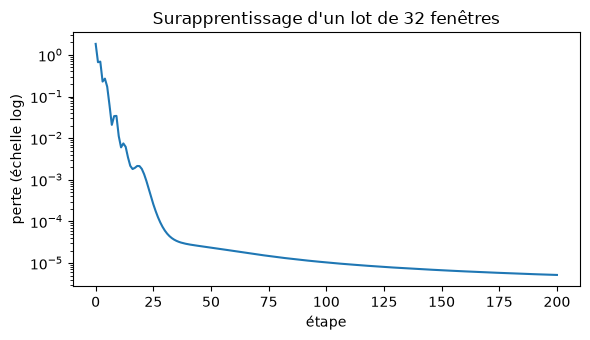

In [22]:
torch.manual_seed(SEED)
modele_test = MLP(N_ENTREES, 64, N_CLASSES, nn.ReLU)
optimiseur = torch.optim.Adam(modele_test.parameters(), lr=1e-2)

# Petit lot : 32 fenêtres tirées au hasard dans l'entraînement
idx = torch.randperm(len(X_tr_t), generator=torch.Generator().manual_seed(SEED))[:32]
X_lot, y_lot = X_tr_t[idx], y_tr_t[idx]
print("Effectif de chaque classe dans le lot :", torch.bincount(y_lot, minlength=N_CLASSES).tolist())

pertes_lot = []
for etape in range(201):
    optimiseur.zero_grad()
    perte = lossfn(modele_test(X_lot), y_lot)
    perte.backward()
    optimiseur.step()
    pertes_lot.append(perte.item())
    if etape in (0, 25, 50, 100, 200):
        print(f"étape {etape:3d} : perte = {perte.item():.4f}")

with torch.no_grad():
    acc_lot = (modele_test(X_lot).argmax(dim=1) == y_lot).float().mean().item()
print("Accuracy finale sur le lot :", acc_lot)

plt.figure(figsize=(6, 3.5))
plt.semilogy(pertes_lot)
plt.xlabel("étape")
plt.ylabel("perte (échelle log)")
plt.title("Surapprentissage d'un lot de 32 fenêtres")
plt.tight_layout()
plt.show()

Sur le lot de 32 fenêtres (les 6 classes y sont présentes), la perte passe de 1,84 à 0,0003 en 25 étapes, et l'accuracy atteint 100 %. Le réseau sait donc apprendre, et les étapes de l'entraînement (remise à zéro des gradients, passage avant, perte, rétropropagation, mise à jour) fonctionnent. Ce n'est pas un résultat de généralisation : c'est seulement un test de bon fonctionnement.

### Conclusion de 2.1

J'ai un réseau 540 → 64 → 6 (ReLU, 35 014 paramètres), une perte initiale conforme à ln(6) et la preuve qu'il sait surapprendre un petit lot. Je peux passer à 2.2, pour comparer les activations et les optimiseurs, en commençant par écrire `train_epoch` et `evaluate`.

## Préparation technique : fonctions d'entraînement et d'évaluation

> Ce n'est pas une question de l'énoncé : la structure 8.1 (étape 4) demande de définir `train_epoch` et `evaluate`, comme dans le TP.

`train_epoch` fait une époque d'entraînement (un passage sur tous les mini-batches). `evaluate` mesure la perte, l'accuracy et le F1 macro sur un jeu de données, sans calculer de gradient. `fit` répète l'entraînement sur plusieurs époques et garde, à chaque époque, la perte et l'accuracy en entraînement et en validation. À chaque essai, je refixe la graine, pour que les comparaisons se fassent dans les mêmes conditions (même initialisation, même ordre des mini-batches).

In [23]:
# Jeu d'entraînement parcouru sans mélange : sert à mesurer ses scores à chaque époque
train_eval_loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=512, shuffle=False)


def train_epoch(model, loader, optimizer, lossfn):
    # Une époque : pour chaque mini-batch, les 5 étapes de l'apprentissage
    model.train()
    total_loss = 0.0
    for X, y in loader:
        optimizer.zero_grad()           # 1. remise à zéro des gradients
        perte = lossfn(model(X), y)     # 2. passage avant + erreur
        perte.backward()                # 3. rétropropagation
        optimizer.step()                # 4. mise à jour des poids
        total_loss += perte.item() * len(y)
    return total_loss / len(loader.dataset)    # erreur moyenne par exemple


def evaluate(model, loader, lossfn):
    # Perte moyenne, accuracy et F1 macro, sans calcul de gradient
    model.eval()
    total_loss, y_vrai, y_pred = 0.0, [], []
    with torch.no_grad():
        for X, y in loader:
            sortie = model(X)
            total_loss += lossfn(sortie, y).item() * len(y)
            y_pred.append(sortie.argmax(dim=1))
            y_vrai.append(y)
    y_vrai = torch.cat(y_vrai).numpy()
    y_pred = torch.cat(y_pred).numpy()
    return (total_loss / len(loader.dataset),
            accuracy_score(y_vrai, y_pred),
            f1_score(y_vrai, y_pred, average="macro"))


# Les trois optimiseurs comparés
OPTIMISEURS = {
    "SGD": lambda p, lr: torch.optim.SGD(p, lr=lr),
    "SGD + momentum": lambda p, lr: torch.optim.SGD(p, lr=lr, momentum=0.9),
    "Adam": lambda p, lr: torch.optim.Adam(p, lr=lr),
}


def fit(activation, optimiseur, lr, n_epochs, n_caches=64, seed=SEED):
    # Entraîne un réseau et renvoie (modèle, historique époque par époque)
    torch.manual_seed(seed)
    model = MLP(N_ENTREES, n_caches, N_CLASSES, activation)
    opt = OPTIMISEURS[optimiseur](model.parameters(), lr)
    loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "val_f1": []}
    for _ in range(n_epochs):
        train_epoch(model, loader, opt, lossfn)
        tl, ta, _ = evaluate(model, train_eval_loader, lossfn)
        vl, va, vf = evaluate(model, val_loader, lossfn)
        for cle, val in zip(hist, (tl, ta, vl, va, vf)):
            hist[cle].append(val)
    return model, hist

## 2.2 Essais : activations, optimiseurs, métriques

> **Demandé :**
> - (a) faire varier la fonction d'activation ;
> - (b) tester SGD, SGD avec momentum et Adam, avec un pas d'apprentissage réglé pour chacun (LR range test ou petite grille logarithmique) ;
> - (c) suivre accuracy et loss en entraînement et en validation à chaque époque ;
> - (d) réfléchir à l'accuracy contre le F1-score (macro et par classe) : quelle métrique est la plus informative ici, et pourquoi ? Cela dépend-il de la distribution des classes de la partie 1 ?
> - puis commenter la convergence, la stabilité, le sous-apprentissage et le surapprentissage.

Mes étapes : 2.2.1 (réglage du pas d'apprentissage, pour (a) et (b)), 2.2.2 (comparaison des optimiseurs, avec (c)), 2.2.3 (comparaison des activations, avec (c)), 2.2.4 (accuracy ou F1, (d)), 2.2.5 (observations).

### 2.2.1 Réglage du pas d'apprentissage

Le meilleur pas d'apprentissage dépend de l'optimiseur et de l'activation, donc je le règle pour chacune des 9 combinaisons (3 activations × 3 optimiseurs). Je teste une petite grille logarithmique (un pas multiplié par environ 3 à chaque fois), avec 30 époques par essai. Je garde le pas qui donne la **perte de validation** la plus basse à la dernière époque : la perte est moins bruitée que l'accuracy. Un essai qui diverge (perte infinie ou `nan`) est écarté automatiquement.

Tout se fait avec une seule graine (42) : c'est une première comparaison. La variabilité entre graines sera mesurée en 2.3.

In [24]:
ACTIVATIONS = {"ReLU": nn.ReLU, "Tanh": nn.Tanh, "Sigmoid": nn.Sigmoid}
GRILLES = {
    "SGD": [1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1.0, 3.0, 10.0],
    "SGD + momentum": [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1],
    "Adam": [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2],
}
N_EPOCHS = 30

# On garde le modèle et l'historique de chaque essai
resultats = {}
for act_nom, act in ACTIVATIONS.items():
    for opt_nom, grille in GRILLES.items():
        for lr in grille:
            resultats[(act_nom, opt_nom, lr)] = fit(act, opt_nom, lr, N_EPOCHS)
print("Nombre d'essais :", len(resultats))


def meilleur_lr(act_nom, opt_nom):
    # Pas qui minimise la perte de validation à la dernière époque (nan -> écarté)
    pertes = {lr: resultats[(act_nom, opt_nom, lr)][1]["val_loss"][-1] for lr in GRILLES[opt_nom]}
    return min(pertes, key=lambda lr: np.nan_to_num(pertes[lr], nan=np.inf))


LR_CHOISI = {(a, o): meilleur_lr(a, o) for a in ACTIVATIONS for o in GRILLES}

Nombre d'essais : 66


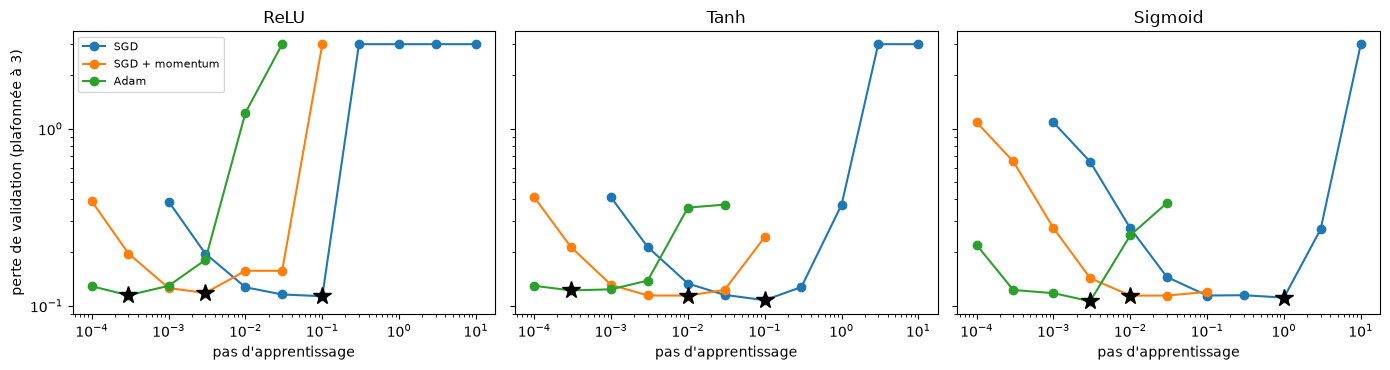

pas choisi  au bord de la grille  \
activation optimiseur                                         
ReLU       SGD                 0.1000                 False   
           SGD + momentum      0.0030                 False   
           Adam                0.0003                 False   
Tanh       SGD                 0.1000                 False   
           SGD + momentum      0.0100                 False   
           Adam                0.0003                 False   
Sigmoid    SGD                 1.0000                 False   
           SGD + momentum      0.0100                 False   
           Adam                0.0030                 False   

                           acc. entraînement  acc. validation  \
activation optimiseur                                           
ReLU       SGD                        0.9987           0.9584   
           SGD + momentum             0.9890           0.9534   
           Adam                       0.9905           0.9556   
Tanh       SGD                        0.9989           0.9578   
           SGD + momentum             0.9986           0.9572   
           Adam                       0.9915           0.9539   
Sigmoid    SGD                        1.0000           0.9628   
           SGD + momentum             0.9870           0.9567   
           Adam                       1.0000           0.9650   

                           F1 macro validation  perte validation  
activation optimiseur                                             
ReLU       SGD                          0.9540            0.1132  
           SGD + momentum               0.9489            0.1181  
           Adam                         0.9521            0.1146  
Tanh       SGD                          0.9538            0.1075  
           SGD + momentum               0.9537            0.1141  
           Adam                         0.9501            0.1221  
Sigmoid    SGD                          0.9589            0.1111  
           SGD + momentum               0.9522            0.1141  
           Adam                         0.9622            0.1061

In [25]:
# Perte de validation (dernière époque) selon le pas d'apprentissage
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, a in zip(axes, ACTIVATIONS):
    for o, grille in GRILLES.items():
        pertes = [np.nan_to_num(resultats[(a, o, lr)][1]["val_loss"][-1], nan=10) for lr in grille]
        ax.plot(grille, np.minimum(pertes, 3), marker="o", label=o)
        lr_ok = LR_CHOISI[(a, o)]
        ax.plot(lr_ok, min(resultats[(a, o, lr_ok)][1]["val_loss"][-1], 3), "k*", markersize=13)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(a)
    ax.set_xlabel("pas d'apprentissage")
axes[0].set_ylabel("perte de validation (plafonnée à 3)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# Récapitulatif : pas choisi et scores pour chaque combinaison
lignes = []
for (a, o), lr in LR_CHOISI.items():
    h = resultats[(a, o, lr)][1]
    lignes.append({"activation": a, "optimiseur": o, "pas choisi": lr,
                   "au bord de la grille": lr in (GRILLES[o][0], GRILLES[o][-1]),
                   "acc. entraînement": h["train_acc"][-1], "acc. validation": h["val_acc"][-1],
                   "F1 macro validation": h["val_f1"][-1], "perte validation": h["val_loss"][-1]})
tableau22 = pd.DataFrame(lignes).set_index(["activation", "optimiseur"]).round(4)
tableau22

Je constate le même schéma pour chaque optimiseur : si le pas est trop petit, la perte de validation reste élevée (30 époques ne suffisent pas pour converger) ; autour du meilleur pas, elle est basse et plate ; si le pas est trop grand, l'entraînement diverge. Les pas utiles sont très différents selon l'optimiseur : de 3×10⁻⁴ à 3×10⁻³ pour Adam, de 0,003 à 0,01 pour SGD avec momentum, de 0,1 à 1 pour SGD seul. Aucun pas choisi n'est au bord de la grille, donc elle est suffisante.

Dans le tableau, les 9 configurations ont entre 95,3 % et 96,5 % d'accuracy en validation (1,2 point d'écart) et une perte de validation entre 0,106 et 0,122. Les écarts sont faibles : avec une seule graine, je ne peux pas encore dire quelle configuration est meilleure (voir 2.3). Autre remarque : seules 2 configurations (Sigmoid avec SGD et Sigmoid avec Adam) dépassent la régression logistique de référence (95,89 %), et de moins d'un point.

### 2.2.2 Comparaison des optimiseurs (suivi par époque)

Je suis la perte et l'accuracy, en entraînement et en validation, à chaque époque. Je compare d'abord les 3 optimiseurs avec ReLU, chacun avec son pas réglé.

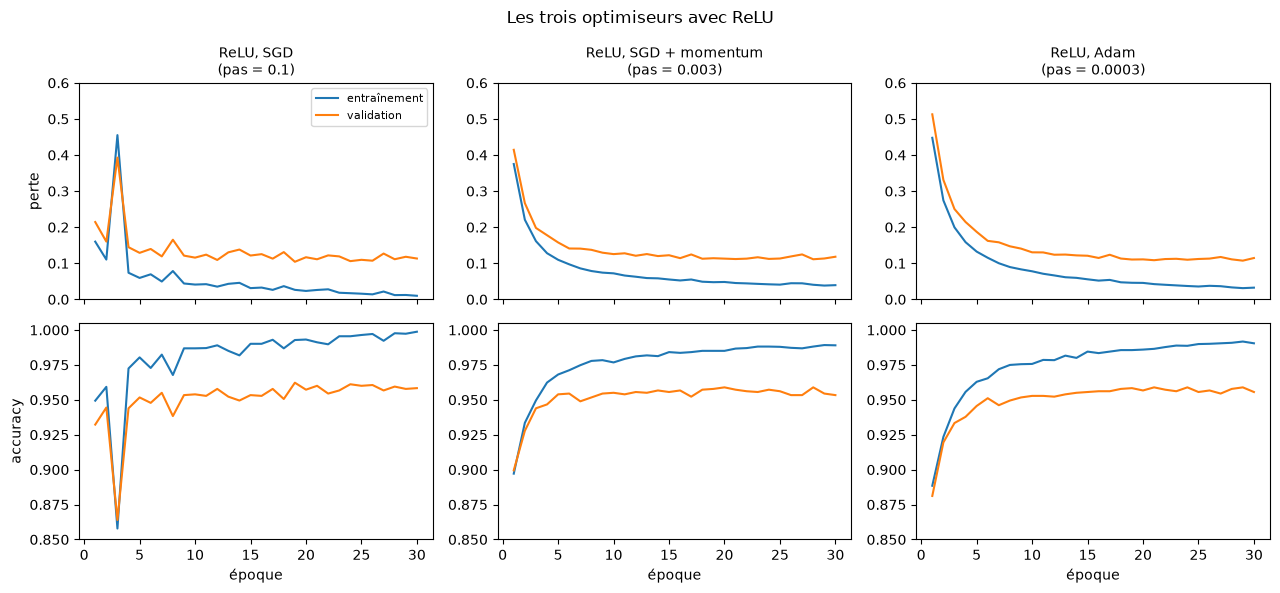

In [26]:
def tracer_courbes(configs, titre):
    # configs : liste de (activation, optimiseur) ; le pas utilisé est celui choisi en 2.2.1
    fig, axes = plt.subplots(2, len(configs), figsize=(4.3 * len(configs), 6), sharex=True)
    epoques = range(1, N_EPOCHS + 1)
    for j, (a, o) in enumerate(configs):
        lr = LR_CHOISI[(a, o)]
        h = resultats[(a, o, lr)][1]
        axes[0, j].plot(epoques, h["train_loss"], label="entraînement")
        axes[0, j].plot(epoques, h["val_loss"], label="validation")
        axes[0, j].set_title(f"{a}, {o}\n(pas = {lr:g})", fontsize=10)
        axes[0, j].set_ylim(0, 0.6)
        axes[1, j].plot(epoques, h["train_acc"], label="entraînement")
        axes[1, j].plot(epoques, h["val_acc"], label="validation")
        axes[1, j].set_ylim(0.85, 1.005)
        axes[1, j].set_xlabel("époque")
    axes[0, 0].set_ylabel("perte")
    axes[1, 0].set_ylabel("accuracy")
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(titre)
    plt.tight_layout()
    plt.show()


tracer_courbes([("ReLU", o) for o in GRILLES], "Les trois optimiseurs avec ReLU")

Avec ReLU, les trois optimiseurs atteignent une perte de validation d'environ 0,11 et une accuracy de validation de 95 à 96 %. SGD avec un pas de 0,1 est instable : à l'époque 3, la perte monte brusquement (environ 0,4) et l'accuracy tombe à 86 %, puis il récupère, mais ses courbes restent plus irrégulières. SGD avec momentum et Adam sont réguliers. Dans les trois cas, la perte d'entraînement continue de baisser alors que celle de validation se stabilise vers l'époque 12 à 15.

### 2.2.3 Comparaison des activations (suivi par époque)

Je compare maintenant les 3 activations avec Adam, chacune avec son pas réglé.

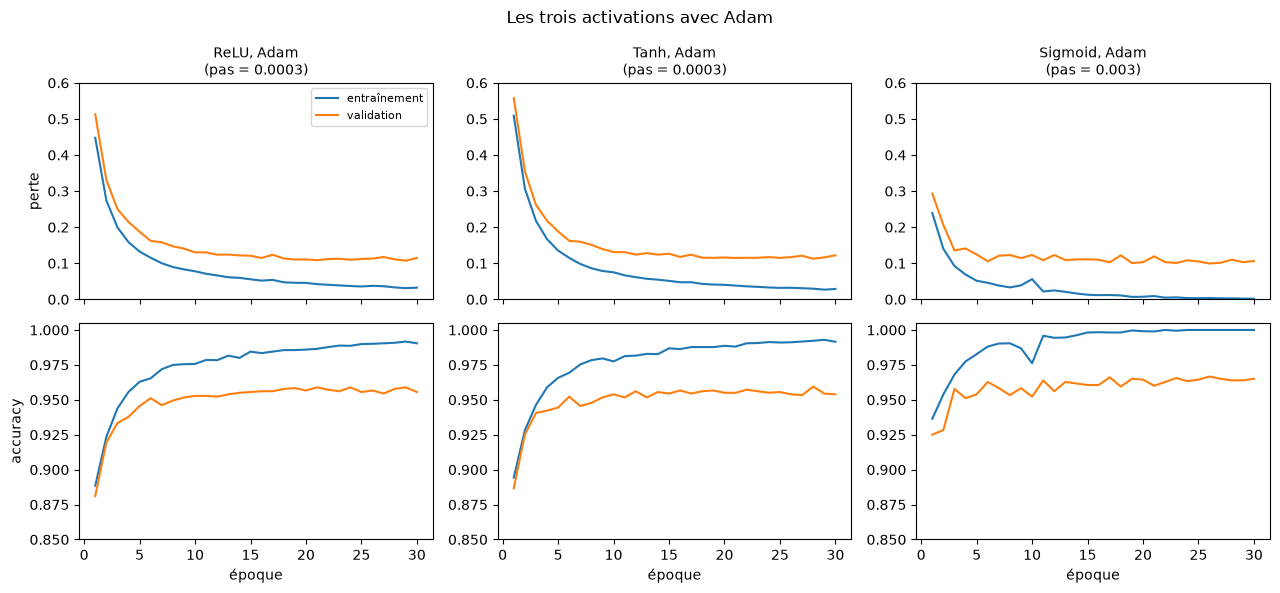

In [27]:
tracer_courbes([(a, "Adam") for a in ACTIVATIONS], "Les trois activations avec Adam")

Avec Adam, ReLU et Tanh donnent des courbes presque identiques (même pas de 3×10⁻⁴). Sigmoid, avec un pas dix fois plus grand (3×10⁻³), apprend plus vite : son accuracy d'entraînement atteint 100 % et sa validation est la plus haute (96,5 %), avec un petit à-coup vers l'époque 10. L'écart entre entraînement et validation est aussi le plus net pour Sigmoid. Sigmoid avec Adam semble meilleure, mais l'écart avec ReLU et Tanh (environ 1 point) est à confirmer sur plusieurs graines.

### 2.2.4 Accuracy ou F1-score ? (d)

Je compare l'accuracy et le F1 macro des 9 configurations, puis je regarde le F1 de chaque classe pour la meilleure d'entre elles (celle de plus faible perte de validation).

In [28]:
# Écart entre accuracy et F1 macro, pour les 9 configurations
ecart = (tableau22["acc. validation"] - tableau22["F1 macro validation"]).abs()
print("Écart |accuracy - F1 macro| sur les 9 configurations : de",
      round(ecart.min(), 4), "à", round(ecart.max(), 4))
print("Pour la régression logistique de référence :",
      round(abs(acc_vol - f1_vol), 4))

# F1 par classe pour la meilleure configuration
a_best, o_best = tableau22["perte validation"].idxmin()
lr_best = LR_CHOISI[(a_best, o_best)]
modele_best = resultats[(a_best, o_best, lr_best)][0]
with torch.no_grad():
    y_pred_best = modele_best(X_val_t).argmax(dim=1).numpy()

print(f"\nMeilleure configuration : {a_best} + {o_best}, pas = {lr_best:g}\n")
print(classification_report(y_val, y_pred_best, target_names=encoder.classes_, digits=3))

Écart |accuracy - F1 macro| sur les 9 configurations : de 0.0028 à 0.0045
Pour la régression logistique de référence : 0.0038

Meilleure configuration : Sigmoid + Adam, pas = 0.003

                    precision    recall  f1-score   support

            LAYING      1.000     0.988     0.994       331
           SITTING      0.950     0.976     0.963       293
          STANDING      0.975     0.963     0.969       321
           WALKING      0.960     0.994     0.977       338
WALKING_DOWNSTAIRS      0.986     0.860     0.918       242
  WALKING_UPSTAIRS      0.922     0.986     0.953       276

          accuracy                          0.965      1801
         macro avg      0.965     0.961     0.962      1801
      weighted avg      0.966     0.965     0.965      1801



Je constate que l'accuracy et le F1 macro sont très proches : l'écart est de 0,3 à 0,45 point pour les 9 configurations, et de 0,4 point pour la régression logistique. Cela vient de la distribution des classes vue en 1.2.2 : elles sont plutôt équilibrées (rapport de 1,4), donc l'accuracy n'est pas dominée par une classe majoritaire. Si une classe était très rare, l'accuracy pourrait rester élevée alors que cette classe serait mal prédite, et le F1 macro serait indispensable.

Le F1 par classe reste pourtant plus informatif ici. Pour la meilleure configuration, l'accuracy de 96,5 % cache que WALKING_DOWNSTAIRS a un recall de seulement 0,860 : environ 14 % des descentes d'escaliers ne sont pas reconnues. Sa precision est de 0,986, alors que celle de WALKING_UPSTAIRS est de 0,922 : je pense que des descentes sont prises pour des montées, comme avec la régression logistique (F1 de 0,902). La matrice de confusion le vérifiera en 5.2. Je retiens donc le F1 macro et le F1 par classe comme métriques principales, en gardant l'accuracy comme repère.

### 2.2.5 Observations : convergence, stabilité, surapprentissage


**Convergence.** Avec un pas bien réglé, les trois optimiseurs convergent en 10 à 15 époques : la perte de validation se stabilise autour de 0,11. Adam et SGD avec momentum ont des courbes régulières.

**Stabilité.** SGD seul avec un pas de 0,1 est instable (à-coup à l'époque 3) et diverge dès 0,3 avec ReLU. La zone de pas utilisable est étroite pour Adam (de 10⁻⁴ à 3×10⁻³) : au-delà de 10⁻², la perte de validation explose. Les pas utiles de SGD sont environ 100 fois plus grands que ceux d'Adam.

**Sous-apprentissage.** Je n'en vois pas avec les pas choisis : l'accuracy d'entraînement atteint 99 à 100 %. Il n'apparaît qu'avec un pas trop petit, où le réseau n'a pas fini d'apprendre en 30 époques.

**Surapprentissage.** Il est net : l'accuracy est de 99 à 100 % en entraînement contre 95 à 96,5 % en validation (écart de 3,5 à 4 points), et la perte d'entraînement continue de baisser alors que celle de validation reste plate vers 0,11. Le réseau retient ses 16 volontaires d'entraînement mieux qu'il ne généralise à de nouvelles personnes. La régularisation (partie 4, dans la Version 2) visera cet écart.

**Bilan.** Les 9 configurations sont toutes entre 95,3 % et 96,5 % d'accuracy en validation, et seulement deux dépassent la régression logistique (95,89 %), de moins d'un point. Avec une seule graine, je ne peux pas conclure que ces écarts sont réels : je mesure la variabilité en 2.3.


## 2.3 Variabilité des résultats

> **Demandé :** pour au moins deux configurations, répéter l'entraînement avec au moins 3 graines et donner la moyenne et l'écart-type des scores. Un écart entre deux configurations plus petit que cette variabilité ne permet pas de conclure. Appliquer ce principe à toutes les comparaisons importantes.

Mes étapes : 2.3.1 (répétition avec 5 graines), 2.3.2 (comparaisons importantes), 2.3.3 (variabilité due au choix des volontaires), 2.3.4 (conclusion).

### 2.3.1 Répétition avec plusieurs graines

Je répète l'entraînement des 9 configurations avec 5 graines différentes (0 à 4), chacune avec le pas choisi en 2.2.1. La graine change l'initialisation du réseau et l'ordre des mini-batches. Le découpage train / validation reste le même (volontaires 1, 3, 15, 25, 27). J'utilise d'autres graines que celle du réglage (42), pour ne pas favoriser les configurations par rapport à ce réglage. Je donne la moyenne et l'écart-type (échantillon à 5 valeurs) à la dernière époque.

In [29]:
SEEDS = [0, 1, 2, 3, 4]

lignes = []
for (a, o), lr in LR_CHOISI.items():
    for graine in SEEDS:
        _, h = fit(ACTIVATIONS[a], o, lr, N_EPOCHS, seed=graine)
        lignes.append({"activation": a, "optimiseur": o, "graine": graine,
                       "acc_train": h["train_acc"][-1], "acc_val": h["val_acc"][-1],
                       "f1_val": h["val_f1"][-1], "perte_val": h["val_loss"][-1]})
graines_df = pd.DataFrame(lignes)
print("Nombre d'entraînements :", len(graines_df))


def moy_std(serie, nd=4):
    return f"{serie.mean():.{nd}f} ± {serie.std():.{nd}f}"


resume = []
for (a, o), d in graines_df.groupby(["activation", "optimiseur"], sort=False):
    resume.append({"activation": a, "optimiseur": o, "pas": LR_CHOISI[(a, o)],
                   "acc. entraînement": moy_std(d["acc_train"]),
                   "acc. validation": moy_std(d["acc_val"]),
                   "F1 macro validation": moy_std(d["f1_val"]),
                   "perte validation": moy_std(d["perte_val"])})
pd.DataFrame(resume).set_index(["activation", "optimiseur"])

Nombre d'entraînements : 45


pas acc. entraînement  acc. validation  \
activation optimiseur                                                  
ReLU       SGD             0.1000   0.9984 ± 0.0005  0.9598 ± 0.0044   
           SGD + momentum  0.0030   0.9891 ± 0.0022  0.9534 ± 0.0023   
           Adam            0.0003   0.9905 ± 0.0018  0.9556 ± 0.0047   
Tanh       SGD             0.1000   0.9979 ± 0.0005  0.9604 ± 0.0040   
           SGD + momentum  0.0100   0.9989 ± 0.0006  0.9604 ± 0.0030   
           Adam            0.0003   0.9922 ± 0.0019  0.9586 ± 0.0019   
Sigmoid    SGD             1.0000   1.0000 ± 0.0001  0.9605 ± 0.0025   
           SGD + momentum  0.0100   0.9874 ± 0.0007  0.9559 ± 0.0027   
           Adam            0.0030   0.9999 ± 0.0002  0.9647 ± 0.0046   

                          F1 macro validation perte validation  
activation optimiseur                                           
ReLU       SGD                0.9553 ± 0.0047  0.1154 ± 0.0131  
           SGD + momentum     0.9484 ± 0.0028  0.1208 ± 0.0075  
           Adam               0.9520 ± 0.0050  0.1162 ± 0.0124  
Tanh       SGD                0.9559 ± 0.0042  0.1087 ± 0.0088  
           SGD + momentum     0.9560 ± 0.0035  0.1094 ± 0.0077  
           Adam               0.9544 ± 0.0023  0.1137 ± 0.0061  
Sigmoid    SGD                0.9560 ± 0.0028  0.1270 ± 0.0081  
           SGD + momentum     0.9509 ± 0.0030  0.1191 ± 0.0040  
           Adam               0.9616 ± 0.0048  0.1070 ± 0.0126

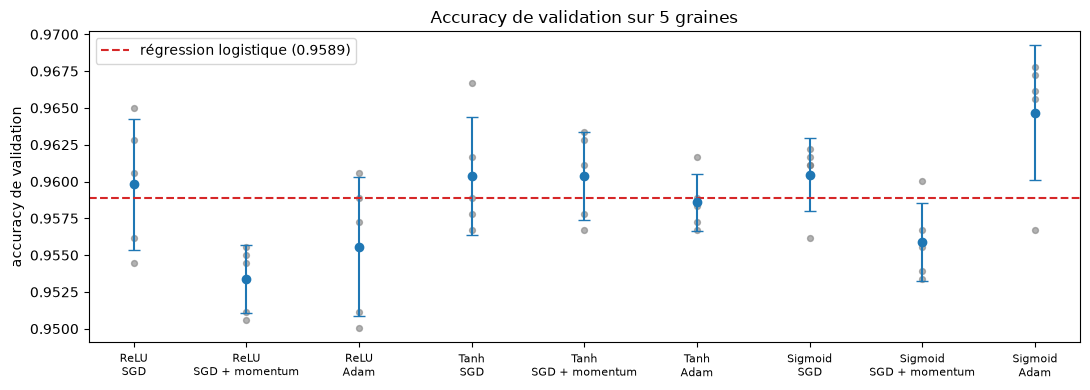

In [30]:
# Chaque point gris est une graine ; le point bleu est la moyenne, avec ± 1 écart-type
fig, ax = plt.subplots(figsize=(11, 4))
noms = []
for k, ((a, o), d) in enumerate(graines_df.groupby(["activation", "optimiseur"], sort=False)):
    ax.scatter([k] * len(d), d["acc_val"], color="gray", alpha=0.6, s=18)
    ax.errorbar(k, d["acc_val"].mean(), yerr=d["acc_val"].std(), fmt="o", color="C0", capsize=4)
    noms.append(f"{a}\n{o}")
ax.axhline(acc_vol, color="C3", linestyle="--", label=f"régression logistique ({acc_vol:.4f})")
ax.set_xticks(range(len(noms)))
ax.set_xticklabels(noms, fontsize=8)
ax.set_ylabel("accuracy de validation")
ax.set_title("Accuracy de validation sur 5 graines")
ax.legend()
plt.tight_layout()
plt.show()

Je constate que l'écart-type de l'accuracy de validation entre graines est de 0,2 à 0,5 point selon la configuration. Les moyennes vont de 95,3 % (ReLU, SGD avec momentum) à 96,5 % (Sigmoid, Adam) : 1,1 point d'écart au total, soit à peine plus de deux écarts-types. Sur la figure, presque toutes les barres d'erreur se chevauchent. Cinq configurations sur neuf ont une moyenne au-dessus de la régression logistique (ligne rouge, 95,89 %), mais de moins d'un point au maximum. L'accuracy d'entraînement reste à 99 à 100 % : le surapprentissage de 2.2 se confirme sur toutes les graines.

### 2.3.2 Les comparaisons importantes

J'applique la règle de l'énoncé : un écart entre deux configurations plus petit que la variabilité ne permet pas de conclure. Je la traduis par un critère simple : je considère qu'une différence est nette si elle dépasse **2 fois le plus grand écart-type** des deux configurations. C'est une règle pratique, pas un test statistique (je n'ai que 5 graines).

Je compare trois groupes : les activations avec Adam, les optimiseurs avec ReLU, et le meilleur réseau contre la régression logistique (qui n'a pas de variabilité de graine : son score est fixe).

In [31]:
def acc_graines(a, o):
    d = graines_df[(graines_df["activation"] == a) & (graines_df["optimiseur"] == o)]
    return d["acc_val"]


def comparer(nom, cfg1, cfg2):
    s1, s2 = acc_graines(*cfg1), acc_graines(*cfg2)
    diff = s1.mean() - s2.mean()
    incertitude = max(s1.std(), s2.std())
    net = abs(diff) > 2 * incertitude
    return {"comparaison": nom, "écart d'accuracy (points)": round(diff * 100, 2),
            "2 × écart-type max (points)": round(2 * incertitude * 100, 2),
            "différence nette ?": "oui" if net else "non"}


comparaisons = [
    comparer("Adam : ReLU contre Tanh", ("ReLU", "Adam"), ("Tanh", "Adam")),
    comparer("Adam : Sigmoid contre ReLU", ("Sigmoid", "Adam"), ("ReLU", "Adam")),
    comparer("Adam : Sigmoid contre Tanh", ("Sigmoid", "Adam"), ("Tanh", "Adam")),
    comparer("ReLU : SGD contre SGD + momentum", ("ReLU", "SGD"), ("ReLU", "SGD + momentum")),
    comparer("ReLU : SGD contre Adam", ("ReLU", "SGD"), ("ReLU", "Adam")),
    comparer("ReLU : SGD + momentum contre Adam", ("ReLU", "SGD + momentum"), ("ReLU", "Adam")),
]

# Meilleur réseau (accuracy moyenne) contre la régression logistique (score fixe)
moyennes = graines_df.groupby(["activation", "optimiseur"])["acc_val"].mean()
a_top, o_top = moyennes.idxmax()
s_top = acc_graines(a_top, o_top)
diff_ref = s_top.mean() - acc_vol
comparaisons.append({"comparaison": f"Meilleur réseau ({a_top}, {o_top}) contre régression logistique",
                     "écart d'accuracy (points)": round(diff_ref * 100, 2),
                     "2 × écart-type max (points)": round(2 * s_top.std() * 100, 2),
                     "différence nette ?": "oui" if abs(diff_ref) > 2 * s_top.std() else "non"})
pd.DataFrame(comparaisons).set_index("comparaison")

,écart d'accuracy (points),2 × écart-type max (points),différence nette ?
comparaison,,,
Adam : ReLU contre Tanh,-0.30,0.95,non
Adam : Sigmoid contre ReLU,0.91,0.95,non
Adam : Sigmoid contre Tanh,0.61,0.91,non
ReLU : SGD contre SGD + momentum,0.64,0.89,non
ReLU : SGD contre Adam,0.42,0.95,non
ReLU : SGD + momentum contre Adam,-0.22,0.95,non
"Meilleur réseau (Sigmoid, Adam) contre régression logistique",0.58,0.91,non


Aucune des 7 comparaisons n'est nette. La plus proche du seuil est Sigmoid contre ReLU avec Adam : 0,91 point d'écart pour un seuil de 0,95. Même le meilleur réseau (Sigmoid avec Adam) n'est pas nettement meilleur que la régression logistique (+0,58 point, pour un seuil de 0,91). Je ne peux donc conclure ni qu'une activation est meilleure, ni qu'un optimiseur l'est. Ce que j'avais écrit en 2.2 avec une seule graine (« Sigmoid avec Adam semble meilleure ») n'est pas confirmé : c'était à la limite de la variabilité.

### 2.3.3 Variabilité due au choix des volontaires de validation

La graine n'est pas la seule source de variabilité : mon score de validation dépend aussi des 5 volontaires réservés. Je mesure cet effet avec la régression logistique (un modèle sans graine, rapide à entraîner) : je tire 10 groupes différents de 5 volontaires parmi les 21 du train, et je regarde l'accuracy de validation de chacun.

In [32]:
def logreg_val(vol_val_liste):
    # Régression logistique entraînée sans ces volontaires, évaluée sur eux
    masque = train["subject"].isin(vol_val_liste)
    X_a = train.loc[~masque, feature_cols].to_numpy()
    y_a = encoder.transform(train.loc[~masque, "Activity"])
    X_b = train.loc[masque, feature_cols].to_numpy()
    y_b = encoder.transform(train.loc[masque, "Activity"])
    sc = StandardScaler().fit(X_a)
    m = LogisticRegression(max_iter=2000, random_state=SEED).fit(sc.transform(X_a), y_a)
    p = m.predict(sc.transform(X_b))
    return accuracy_score(y_b, p), f1_score(y_b, p, average="macro")


rng = np.random.RandomState(0)
tirages = [sorted(rng.choice(volontaires, size=5, replace=False).tolist()) for _ in range(10)]
scores = [logreg_val(t) for t in tirages]

tab_tirages = pd.DataFrame({"volontaires de validation": [str(t) for t in tirages],
                            "accuracy": [round(s[0], 4) for s in scores],
                            "F1 macro": [round(s[1], 4) for s in scores]})
print(tab_tirages.to_string(index=False))

acc_t = np.array([s[0] for s in scores])
print(f"\nAccuracy sur 10 tirages : {acc_t.mean():.4f} ± {acc_t.std(ddof=1):.4f}"
      f" (min {acc_t.min():.4f}, max {acc_t.max():.4f})")
print(f"Mon tirage (1, 3, 15, 25, 27) : {acc_vol:.4f}")

volontaires de validation  accuracy  F1 macro
      [3, 15, 19, 22, 30]    0.9579    0.9545
     [11, 14, 17, 26, 30]    0.9282    0.9266
     [11, 22, 26, 28, 29]    0.9538    0.9552
     [15, 22, 26, 28, 30]    0.9601    0.9601
       [1, 3, 14, 16, 28]    0.8624    0.8668
     [11, 15, 19, 21, 26]    0.9634    0.9629
       [1, 8, 14, 15, 17]    0.9120    0.9096
        [3, 7, 8, 14, 28]    0.8722    0.8694
      [3, 14, 22, 26, 29]    0.9285    0.9234
      [6, 21, 23, 26, 27]    0.9584    0.9579

Accuracy sur 10 tirages : 0.9297 ± 0.0371 (min 0.8624, max 0.9634)
Mon tirage (1, 3, 15, 25, 27) : 0.9589


Je constate que le choix des 5 volontaires compte beaucoup plus que la graine. Sur 10 tirages, l'accuracy de la régression logistique va de 86,2 % à 96,3 % (moyenne de 93,0 %, écart-type de 3,7 points), contre 0,2 à 0,5 point pour la graine. Mon tirage (95,9 %) est parmi les plus favorables : seuls 2 tirages sur 10 font mieux.

Cela a trois conséquences. Les scores absolus de validation sont probablement plus élevés que ce que j'obtiendrais avec d'autres volontaires. Les comparaisons entre configurations, faites sur les mêmes volontaires, restent utiles mais rien ne garantit que leur ordre se conserve avec d'autres personnes. Enfin, le score de test dépendra lui aussi des 9 volontaires du test, et pourra être différent de celui de la validation. Cette mesure ne porte que sur la régression logistique : pour les réseaux, il faudrait refaire le réglage à chaque tirage, ce qui coûterait cher. Une validation croisée par volontaire serait une amélioration possible pour la Version 2.

### 2.3.4 Conclusion de 2.3


**Ce que j'en retiens.**
- La variabilité due à la graine est de 0,2 à 0,5 point d'accuracy. Celle due au choix des volontaires est bien plus grande (3,7 points d'écart-type avec la régression logistique).
- Aucune activation ni aucun optimiseur n'est nettement meilleur qu'un autre, et aucun réseau ne bat nettement la régression logistique de référence. Avec ces données, un MLP à une couche cachée ne fait pas mieux qu'un modèle linéaire sur ces variables déjà très informatives.
- Je ne choisirai donc pas une configuration sur de petits écarts : toutes mes comparaisons importantes seront faites avec plusieurs graines, et je les lirai avec la règle des 2 écarts-types.

**Pour la suite.** Je prends ReLU avec Adam (pas de 3×10⁻⁴) comme configuration de départ en 3.1. Ce n'est pas parce qu'elle est meilleure (elle ne l'est pas nettement), mais parce que ReLU supporte mieux les réseaux plus profonds de la Version 2 : avec la sigmoïde, le gradient diminue à chaque couche traversée (cours, partie I).


# Partie 3 : Extension de l'architecture

> **Ce qui est demandé dans cette partie :** augmenter la taille de la couche cachée (3.1), puis tester des réseaux plus profonds (3.2, dans le notebook Version 2).

## 3.1 Taille de la couche cachée

> **Demandé :** augmenter progressivement la taille de la couche cachée (par exemple 128, 256 neurones), analyser l'impact sur les performances et sur le surapprentissage, et indiquer le nombre de paramètres de chaque modèle.

*À compléter.*

# Partie 5 : Visualisation et analyse des performances

> **Ce qui est demandé dans cette partie :** tracer les courbes d'apprentissage (5.1), puis évaluer une seule fois sur le test les configurations retenues et la référence de 1.4, avec la matrice de confusion (5.2).

## 5.1 Courbes d'apprentissage

> **Demandé :** tracer l'évolution de la loss et de l'accuracy (ou du F1-score), en entraînement et en validation, au cours des époques, pour suivre la convergence et détecter un surapprentissage ou un sous-apprentissage.

*À compléter.*

## 5.2 Évaluation finale et matrice de confusion

> **Demandé :** évaluer **une seule fois** sur le test les 2 ou 3 configurations retenues ainsi que la référence de 1.4, et comparer ces scores à ceux de la validation. Calculer et visualiser la matrice de confusion sur le test, commenter les classes les plus difficiles à prédire, et dire si les confusions sont plausibles du point de vue des capteurs.
>
> **À faire ici aussi :** répondre à la question laissée ouverte en 1.3 (b) : entre le découpage aléatoire et le découpage par volontaire, lequel donne une validation plus proche du score de test de la régression logistique ?

*À compléter.*